# Initiation à OpenCV — Notebook à trous

Ce notebook a pour but de vous initier à la bibliothèque **OpenCV**, une bibliothèque open-source très populaire pour la **vision par ordinateur**. Nous allons couvrir les bases de la manipulation d'images, les espaces de couleur, les transformations géométriques, et des techniques de segmentation pour compter des oiseaux dans une image.

**Consigne** : ce notebook contient des trous marqués par `# À COMPLÉTER` ou `...`. Complétez le code à chaque endroit indiqué en vous appuyant sur la théorie donnée et sur la documentation d'OpenCV.

---

## Prérequis

Pour exécuter ce notebook, assurez-vous d'avoir installé les bibliothèques nécessaires. Si ce n'est pas déjà fait, exécutez la commande suivante dans votre terminal ou directement dans une cellule de code :

```bash
pip install opencv-python numpy matplotlib ipywidgets
```

> **Remarque** : Le package pip d'OpenCV s'appelle `opencv-python`, mais la bibliothèque s'importe avec le nom `cv2`.

In [1]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, widgets

## 1. Chargement et affichage de l'image

### Théorie
OpenCV lit les images en **BGR** (Bleu, Vert, Rouge) par défaut, alors que Matplotlib utilise le format **RGB** (Rouge, Vert, Bleu). Il est donc nécessaire de convertir l'image de BGR à RGB pour un affichage correct.

**À faire** : chargez l'image, convertissez-la dans le bon espace de couleur pour l'affichage, puis affichez-la.

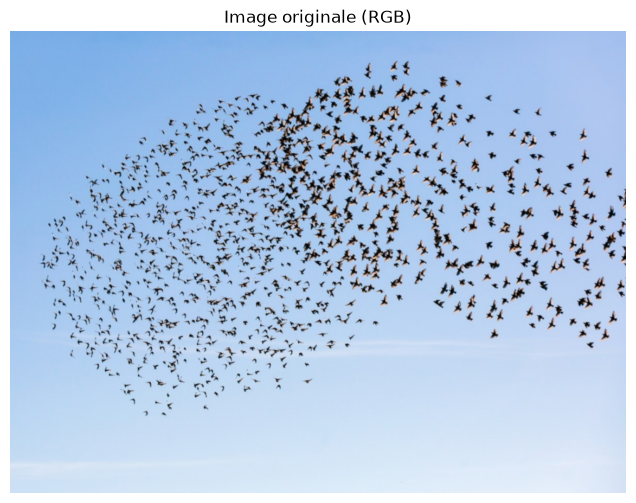

Dimensions de l'image : 1200x900 pixels


In [2]:
# Charger l'image (remplacez par le chemin de votre image)
try:
    img_bgr = cv.imread("birds_low.jpg")
    if img_bgr is None:
        raise FileNotFoundError("L'image n'a pas été trouvée. Vérifiez le chemin.")
    
    # Convertir de BGR à RGB pour un affichage correct
    img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)
    
    # Afficher l'image
    plt.figure(figsize=(10, 6))
    plt.imshow(img_rgb)
    plt.title("Image originale (RGB)")
    plt.axis('off')
    plt.show()
    
    # Afficher les dimensions de l'image
    print(f"Dimensions de l'image : {img_rgb.shape[1]}x{img_rgb.shape[0]} pixels")
    
except Exception as e:
    print(f"Erreur : {e}")

## 2. Conversion entre espaces de couleur

### Théorie
Les espaces de couleur comme **BGR**, **RGB**, **LAB**, **HLS** ou **Grayscale** ont chacun leurs avantages :
- **RGB/BGR** : Utilisés pour l'affichage.
- **Grayscale** : Simplifie le traitement en réduisant à une seule dimension (intensité lumineuse).
- **HLS/HSV** : Utile pour la segmentation basée sur la teinte (Hue).
- **LAB** : Proche de la perception humaine des couleurs, utile pour la segmentation par distance euclidienne.

**À faire** : convertissez `img_rgb` en niveaux de gris, en LAB et en HLS.

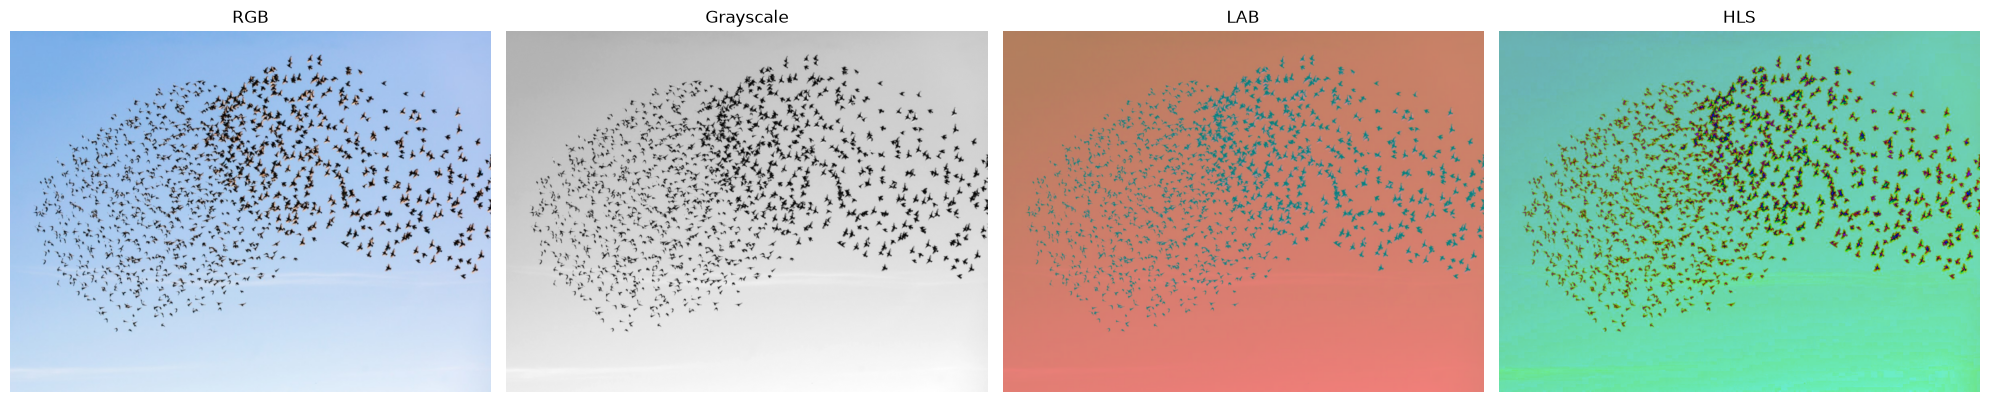

In [3]:
# Convertir l'image en différents espaces de couleur
img_gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)
img_lab = cv.cvtColor(img_bgr, cv.COLOR_BGR2LAB)
img_hls = cv.cvtColor(img_bgr, cv.COLOR_BGR2HLS)


# Afficher les images
fig, ax = plt.subplots(1, 4, figsize=(20, 5))
images = [img_rgb, img_gray, img_lab, img_hls]
titles = ["RGB", "Grayscale", "LAB", "HLS"]
for i, (img, title) in enumerate(zip(images, titles)):
    if len(img.shape) == 2:  # Si l'image est en niveaux de gris
        ax[i].imshow(img, cmap='gray')
    else:
        ax[i].imshow(img)
    ax[i].set_title(title)
    ax[i].axis('off')

plt.tight_layout()
plt.show()

## 3. Région d'Intérêt (ROI) et Canaux de couleur

### Théorie
- **ROI (Region of Interest)** : Sélection d'une partie spécifique de l'image pour un traitement ciblé.
- **Canaux de couleur** : Une image RGB est composée de 3 canaux (Rouge, Vert, Bleu). On peut les séparer pour analyser chaque composante individuellement.

**À faire** : séparez les 3 canaux de `img_rgb`, puis sélectionnez une ROI par slicing numpy.

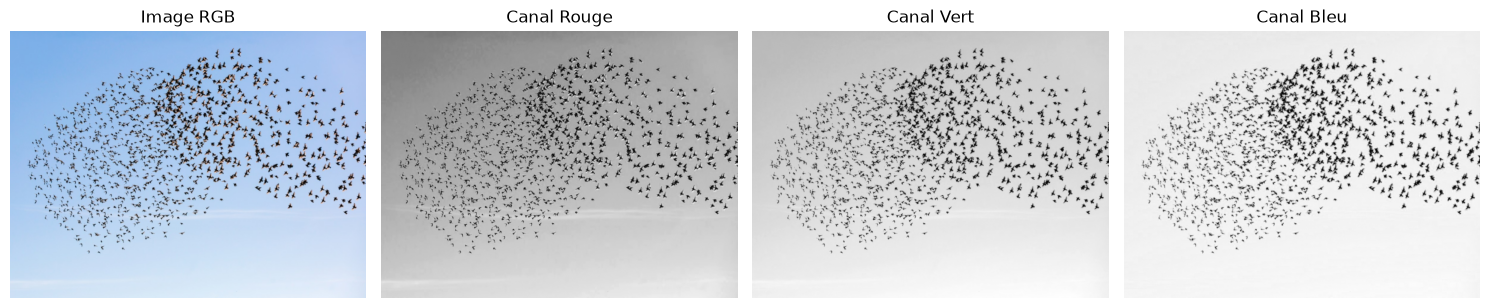

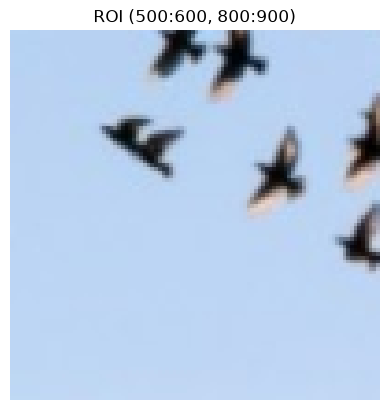

True

In [4]:
# 1. Séparer les canaux RGB
r, g, b = cv.split(img_rgb)

# 2. Afficher chaque canal individuellement
fig, ax = plt.subplots(1, 4, figsize=(15, 5))
ax[0].imshow(img_rgb)
ax[0].set_title("Image RGB")
ax[0].axis('off')

ax[1].imshow(r, cmap='gray')
ax[1].set_title("Canal Rouge")
ax[1].axis('off')

ax[2].imshow(g, cmap='gray')
ax[2].set_title("Canal Vert")
ax[2].axis('off')

ax[3].imshow(b, cmap='gray')
ax[3].set_title("Canal Bleu")
ax[3].axis('off')

plt.tight_layout()
plt.show()

# 3. Sélectionner une ROI (exemple : 500:600, 800:900)
roi = img_rgb[500:600, 800:900]
plt.imshow(roi)
plt.title("ROI (500:600, 800:900)")
plt.axis('off')
plt.show()

# Sauvegarder la ROI
cv.imwrite("roi_oiseau.png", cv.cvtColor(roi, cv.COLOR_RGB2BGR))

## 4. Transformations géométriques

### Théorie
Les transformations géométriques permettent de modifier la taille, l'orientation ou la symétrie d'une image. Cela est utile pour :
- **Réduire la taille** : Accélérer les traitements.
- **Tourner** : Corriger l'orientation.
- **Retourner** : Créer des effets miroir.

**À faire** : redimensionnez l'image, effectuez une rotation de 90° et une rotation de 45°, puis appliquez des symétries horizontale et verticale.

Nouvelle taille : 120x90 pixels


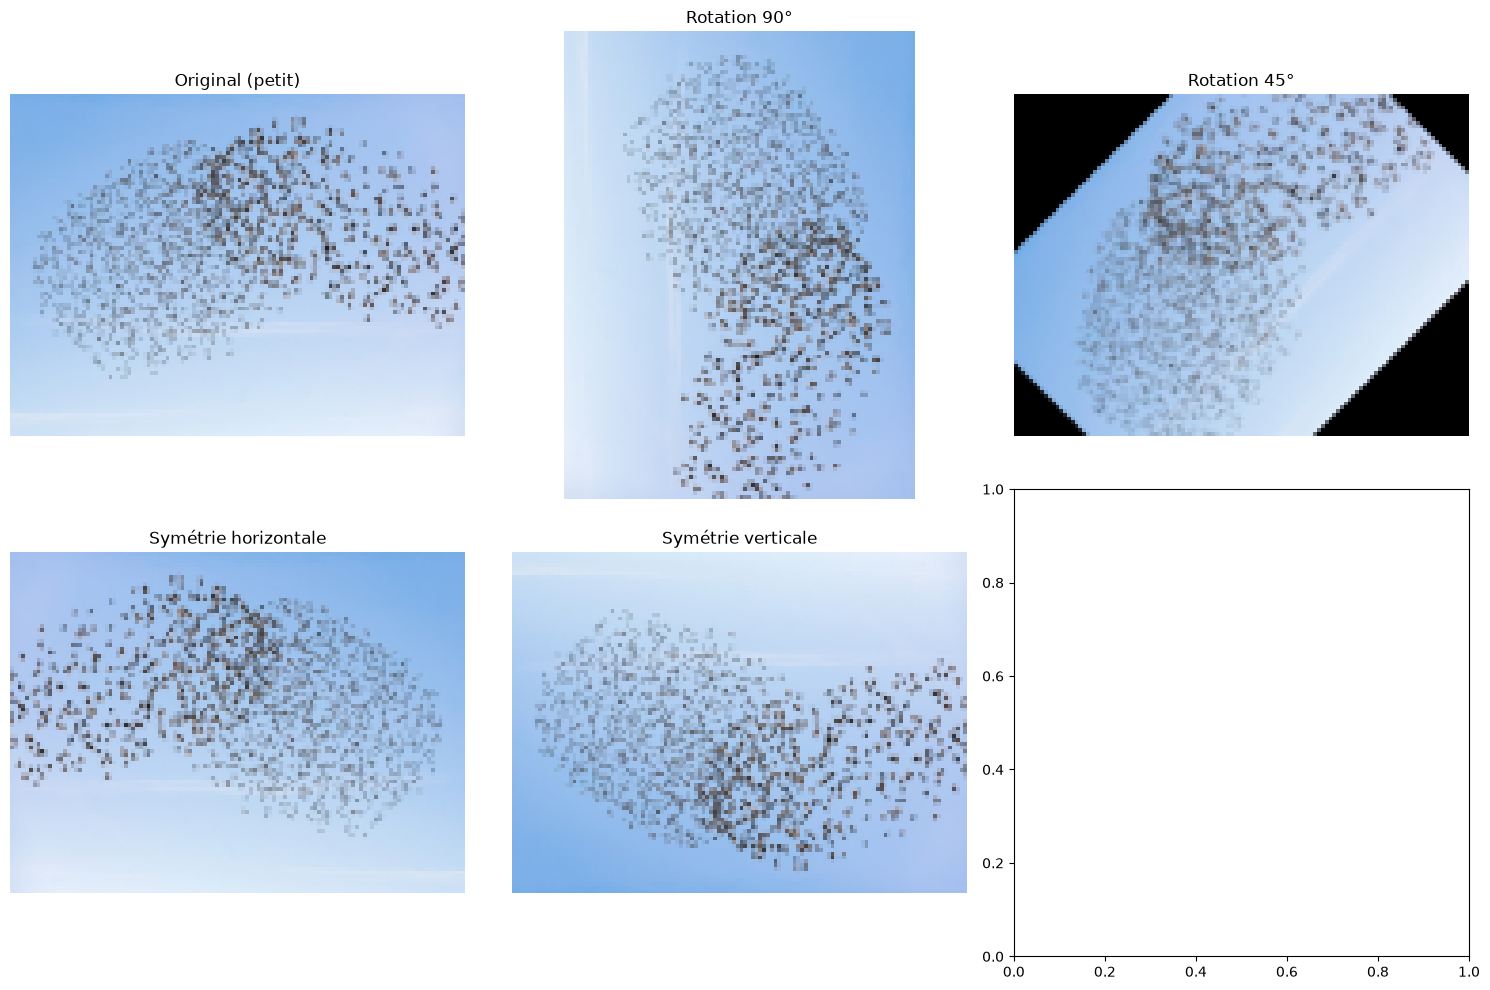

In [5]:
# 1. Redimensionner l'image (diviser par 10)
height, width = img_rgb.shape[:2]
img_small = cv.resize(img_rgb, (width // 10, height // 10), interpolation=cv.INTER_AREA)
print(f"Nouvelle taille : {img_small.shape[1]}x{img_small.shape[0]} pixels")

# 2. Rotations
# Rotation de 90° dans le sens horaire
img_rotated_90 = cv.rotate(img_small, cv.ROTATE_90_CLOCKWISE)

# Rotation de 45° (nécessite une matrice de rotation)
M = cv.getRotationMatrix2D((img_small.shape[1] / 2, img_small.shape[0] / 2), 45, 1.0)
img_rotated_45 = cv.warpAffine(img_small, M, (img_small.shape[1], img_small.shape[0]))

# 3. Symétries
img_flip_horizontal = cv.flip(img_small, 1)
img_flip_vertical = cv.flip(img_small, 0)

# Afficher les résultats
fig, ax = plt.subplots(2, 3, figsize=(15, 10))
images = [img_small, img_rotated_90, img_rotated_45, img_flip_horizontal, img_flip_vertical]
titles = ["Original (petit)", "Rotation 90°", "Rotation 45°", "Symétrie horizontale", "Symétrie verticale"]

for i, (img, title) in enumerate(zip(images, titles)):
    ax[i // 3, i % 3].imshow(img)
    ax[i // 3, i % 3].set_title(title)
    ax[i // 3, i % 3].axis('off')

plt.tight_layout()
plt.show()

## 5. Segmentation par seuillage

### Théorie
Le **seuillage** (thresholding) convertit une image en niveaux de gris en une image binaire, où les pixels sont soit noirs (0) soit blancs (255). Cela permet de séparer les objets d'intérêt de l'arrière-plan.

- **Seuillage manuel** : Définir un seuil fixe.
- **Seuillage d'Otsu** : Calcule automatiquement un seuil optimal.
- **Seuillage adaptatif** : Calcule un seuil local pour chaque pixel.

**À faire** : convertissez `img_small` en niveaux de gris, puis appliquez les trois méthodes de seuillage.

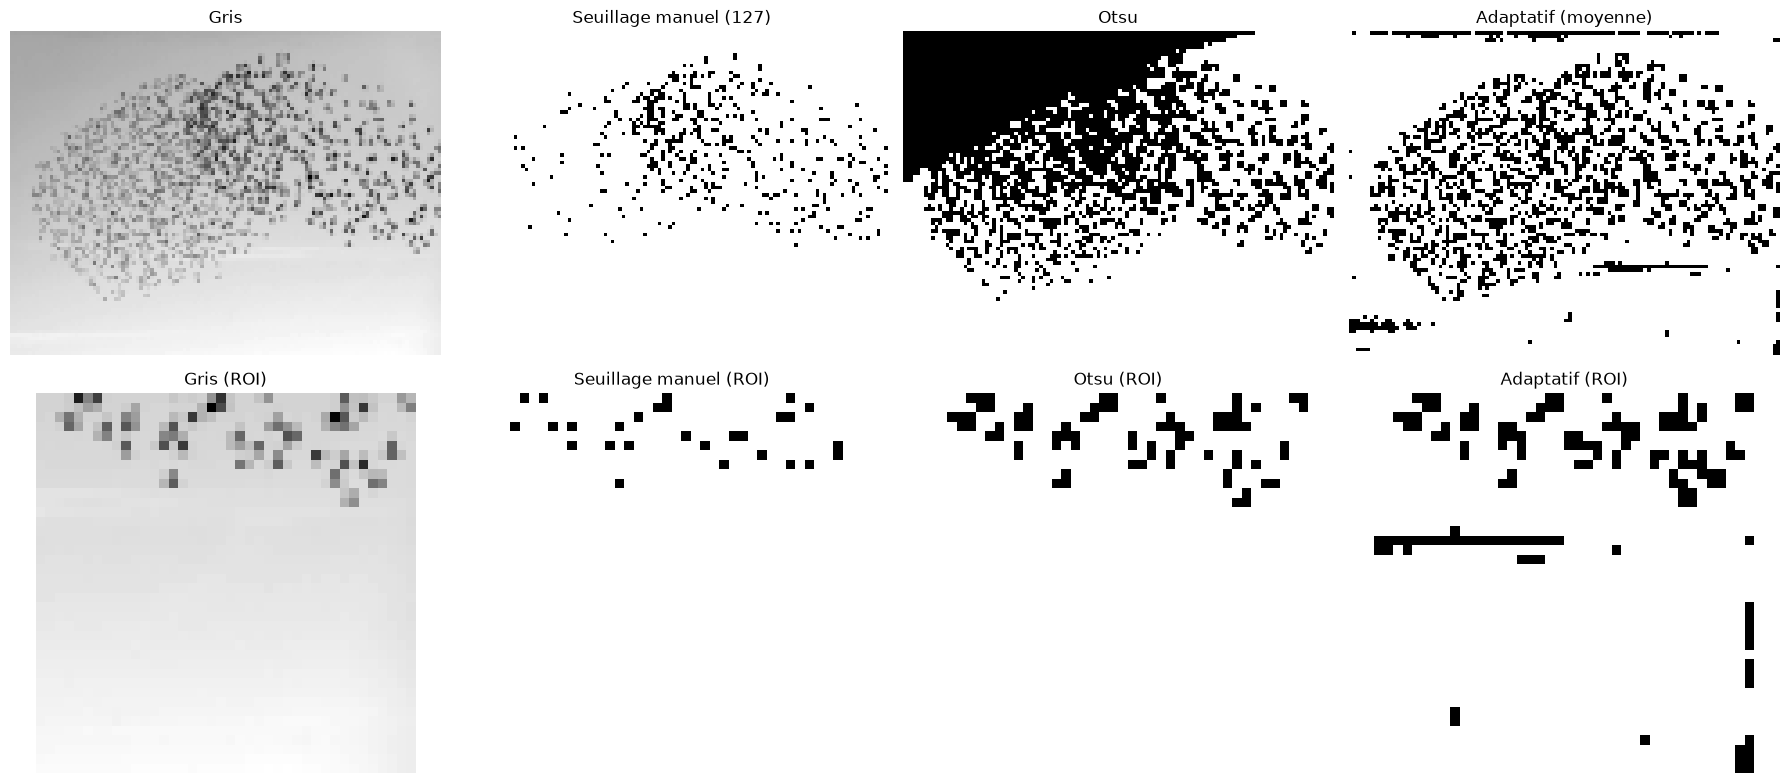

In [6]:
# Convertir l'image petite en niveaux de gris
img_gray_small = cv.cvtColor(img_small, cv.COLOR_RGB2GRAY)

# 1. Seuillage manuel
_, thresh_manual = cv.threshold(img_gray_small, 127, 255, cv.THRESH_BINARY)

# 2. Seuillage d'Otsu
_, thresh_otsu = cv.threshold(img_gray_small, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

# 3. Seuillage adaptatif
thresh_adapt = cv.adaptiveThreshold(img_gray_small, 255, cv.ADAPTIVE_THRESH_MEAN_C, cv.THRESH_BINARY, 11, 2)

# Afficher les résultats
fig, ax = plt.subplots(2, 4, figsize=(18, 8))

# Ligne 1 : Images complètes
images_full = [img_gray_small, thresh_manual, thresh_otsu, thresh_adapt]
titles_full = ["Gris", "Seuillage manuel (127)", "Otsu", "Adaptatif (moyenne)"]

for i, (img, title) in enumerate(zip(images_full, titles_full)):
    ax[0, i].imshow(img, cmap='gray')
    ax[0, i].set_title(title)
    ax[0, i].axis('off')

# Ligne 2 : ROI (exemple : 50:100, 80:130)
roi_coords = (slice(50, 100), slice(80, 130))
images_roi = [img_gray_small[roi_coords], thresh_manual[roi_coords], 
              thresh_otsu[roi_coords], thresh_adapt[roi_coords]]
titles_roi = ["Gris (ROI)", "Seuillage manuel (ROI)", "Otsu (ROI)", "Adaptatif (ROI)"]

for i, (img, title) in enumerate(zip(images_roi, titles_roi)):
    ax[1, i].imshow(img, cmap='gray')
    ax[1, i].set_title(title)
    ax[1, i].axis('off')

plt.tight_layout()
plt.show()

## 6. Segmentation par couleur dans l'espace HLS

### Théorie
L'espace **HLS** (Teinte, Luminosité, Saturation) est utile pour segmenter des objets en fonction de leur **teinte** (Hue). Par exemple, le ciel a souvent une teinte bleue spécifique.

**À faire** : utilisez le curseur pour explorer l'espace HLS et complétez la fonction de visualisation d'une couleur.

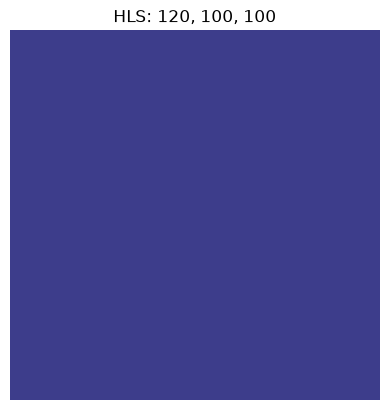

interactive(children=(IntSlider(value=120, description='Hue', max=255), IntSlider(value=100, description='Ligh…

<function __main__.update_pixel_color(h, l, s)>

In [7]:
import ipywidgets as widgets
from ipywidgets import interact

def update_pixel_color(h, l, s):
    pixel = np.array([[[h, l, s]]], dtype=np.uint8)
    pixel_rgb = cv.cvtColor(pixel, cv.COLOR_HLS2RGB)
    plt.imshow(pixel_rgb)
    plt.title(f'HLS: {h}, {l}, {s}')
    plt.axis('off')
    plt.show()

interact(update_pixel_color,
         h=widgets.IntSlider(min=0, max=255, step=1, value=120, description='Hue'),
         l=widgets.IntSlider(min=0, max=255, step=1, value=100, description='Lightness'),
         s=widgets.IntSlider(min=0, max=255, step=1, value=100, description='Saturation'))

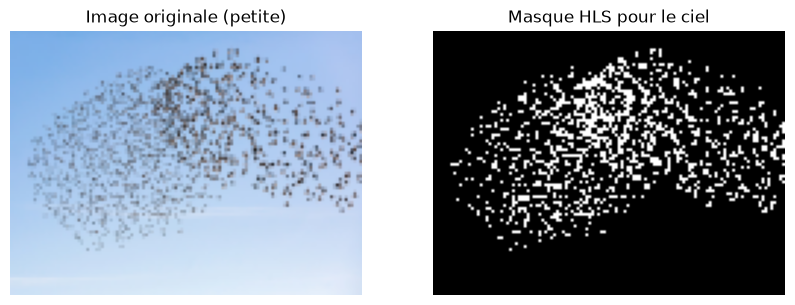

In [8]:
# Convertir l'image petite en HLS
img_hls_small = cv.cvtColor(img_small, cv.COLOR_RGB2HLS)

# Définir les plages pour le ciel (à ajuster selon l'image)
# Exemple : Teinte bleue entre 80 et 120, Luminosité entre 0 et 255, Saturation entre 0 et 50
lower_blue = np.array([80, 0, 0], dtype=np.uint8)
upper_blue = np.array([120, 255, 80], dtype=np.uint8)

# Appliquer le seuillage sur le canal HLS
mask_hls = cv.inRange(img_hls_small, lower_blue, upper_blue)

# Afficher le masque
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(img_small)
plt.title("Image originale (petite)")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(mask_hls, cmap='gray')
plt.title("Masque HLS pour le ciel")
plt.axis('off')
plt.show()

## 7. Segmentation par distance euclidienne dans l'espace LAB

### Théorie
L'espace **LAB** est conçu pour être proche de la perception humaine des couleurs. La **distance euclidienne** entre deux couleurs dans cet espace reflète bien leur différence perçue.

**À faire** : extrayez la couleur LAB d'un pixel du ciel, calculez une carte de distance, normalisez-la, puis seuillez-la pour obtenir un masque binaire.

Valeur LAB du ciel : [202 127 107]


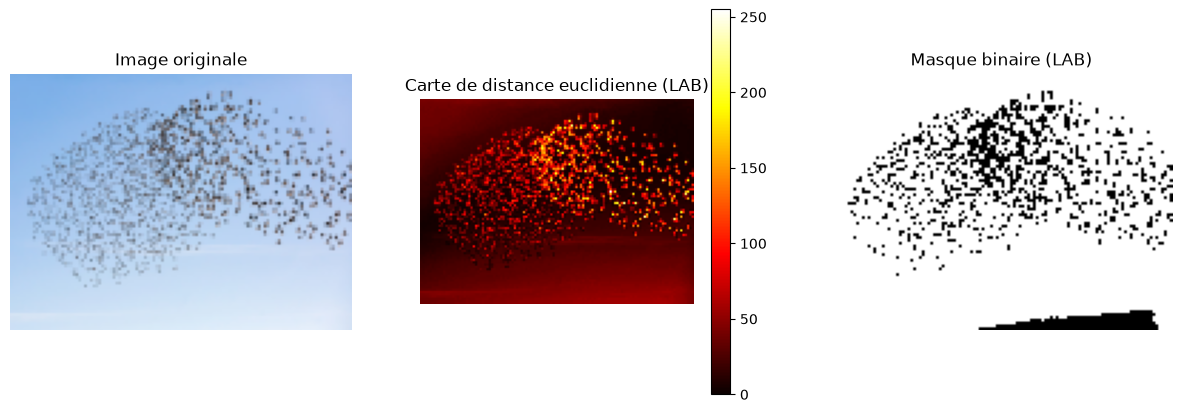

In [9]:
# Convertir l'image petite en LAB
img_lab_small = cv.cvtColor(img_small, cv.COLOR_RGB2LAB)

# Extraire un pixel du ciel (exemple : position (40, 80))
sky_pixel = img_lab_small[40, 80]
print(f"Valeur LAB du ciel : {sky_pixel}")

# Calculer la distance euclidienne entre chaque pixel et la valeur du ciel
# Utiliser np.linalg.norm avec axis=2 pour calculer la norme le long du dernier axe
blue_map = np.linalg.norm(img_lab_small.astype(np.float32) - sky_pixel.astype(np.float32), axis=2)

# Normaliser la carte de distance pour un meilleur affichage
blue_map_normalized = cv.normalize(blue_map, None, 0, 255, cv.NORM_MINMAX).astype(np.uint8)

# Seuiller la carte de distance pour obtenir un masque binaire
_, mask_lab = cv.threshold(blue_map_normalized, 50, 255, cv.THRESH_BINARY_INV)

# Afficher les résultats
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(img_small)
plt.title("Image originale")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(blue_map_normalized, cmap='hot')
plt.title("Carte de distance euclidienne (LAB)")
plt.colorbar()
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(mask_lab, cmap='gray')
plt.title("Masque binaire (LAB)")
plt.axis('off')
plt.show()

## 8. Visualisation des masques sur l'image originale

### Théorie
Pour visualiser l'effet des masques, on peut :
1. **Inverser le masque du ciel** pour obtenir un masque des oiseaux.
2. **Appliquer le masque** à l'image originale avec `cv.bitwise_and`.
3. **Superposer un masque coloré** (ex: rouge) pour mieux voir les zones segmentées.

**À faire** : inversez les masques du ciel, appliquez-les à l'image, puis créez une superposition rouge semi-transparente.

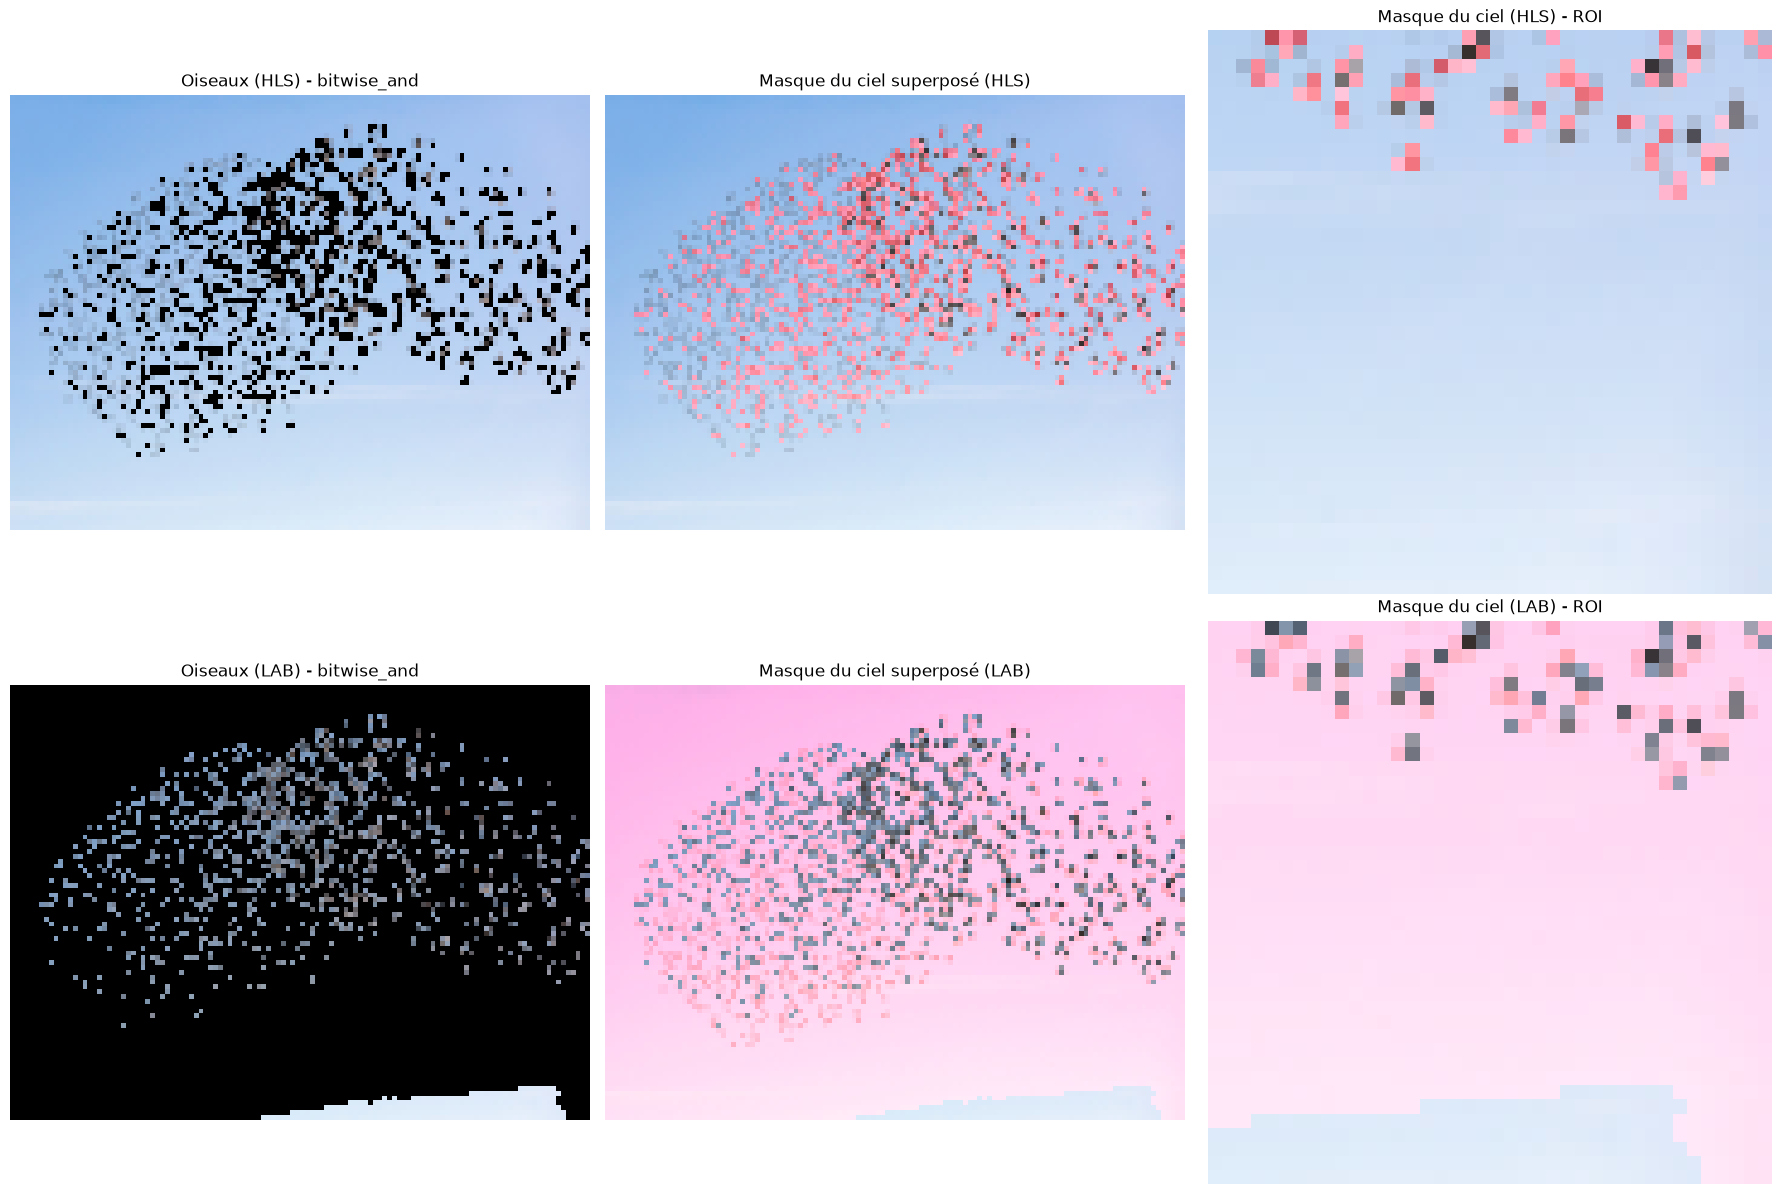

In [10]:
# 1. Inverser le masque du ciel (pour obtenir les oiseaux)
mask_birds_hls = cv.bitwise_not(mask_hls)
mask_birds_lab = cv.bitwise_not(mask_lab)

# 2. Appliquer le masque à l'image originale
birds_only_hls = cv.bitwise_and(img_small, img_small, mask=mask_birds_hls)
birds_only_lab = cv.bitwise_and(img_small, img_small, mask=mask_birds_lab)

# 3. Superposer un masque rouge semi-transparent
# Créer une image rouge avec le masque du ciel
mask_rgb = np.zeros_like(img_small)
mask_rgb[:, :, 0] = 255  # Canal rouge à 255
mask_rgb[:, :, 1] = 0    # Canal vert à 0
mask_rgb[:, :, 2] = 0    # Canal bleu à 0

# Appliquer le masque du ciel à l'image rouge
overlay_hls = cv.bitwise_and(mask_rgb, mask_rgb, mask=mask_hls)
overlay_lab = cv.bitwise_and(mask_rgb, mask_rgb, mask=mask_lab)

# Superposer avec l'image originale
alpha = 0.5  # Transparence
display_image_hls = cv.addWeighted(img_small, 1.0, overlay_hls, alpha, 0)
display_image_lab = cv.addWeighted(img_small, 1.0, overlay_lab, alpha, 0)

# Afficher les résultats
fig, ax = plt.subplots(2, 3, figsize=(18, 12))

# Ligne 1 : Masque HLS
ax[0, 0].imshow(birds_only_hls)
ax[0, 0].set_title("Oiseaux (HLS) - bitwise_and")
ax[0, 0].axis('off')

ax[0, 1].imshow(display_image_hls)
ax[0, 1].set_title("Masque du ciel superposé (HLS)")
ax[0, 1].axis('off')

ax[0, 2].imshow(display_image_hls[50:100, 80:130])
ax[0, 2].set_title("Masque du ciel (HLS) - ROI")
ax[0, 2].axis('off')

# Ligne 2 : Masque LAB
ax[1, 0].imshow(birds_only_lab)
ax[1, 0].set_title("Oiseaux (LAB) - bitwise_and")
ax[1, 0].axis('off')

ax[1, 1].imshow(display_image_lab)
ax[1, 1].set_title("Masque du ciel superposé (LAB)")
ax[1, 1].axis('off')

ax[1, 2].imshow(display_image_lab[50:100, 80:130])
ax[1, 2].set_title("Masque du ciel (LAB) - ROI")
ax[1, 2].axis('off')

plt.tight_layout()
plt.show()

## 9. Contours et mesures géométriques

### Théorie
Les **contours** permettent de détecter les frontières des objets dans une image binaire. On peut ensuite :
- **Compter les objets** (nombre de contours).
- **Calculer des propriétés** (aire, périmètre).
- **Dessiner les contours** ou les **boîtes englobantes**.

**À faire** : trouvez les contours du masque des oiseaux et dessinez-les sur une copie de l'image.

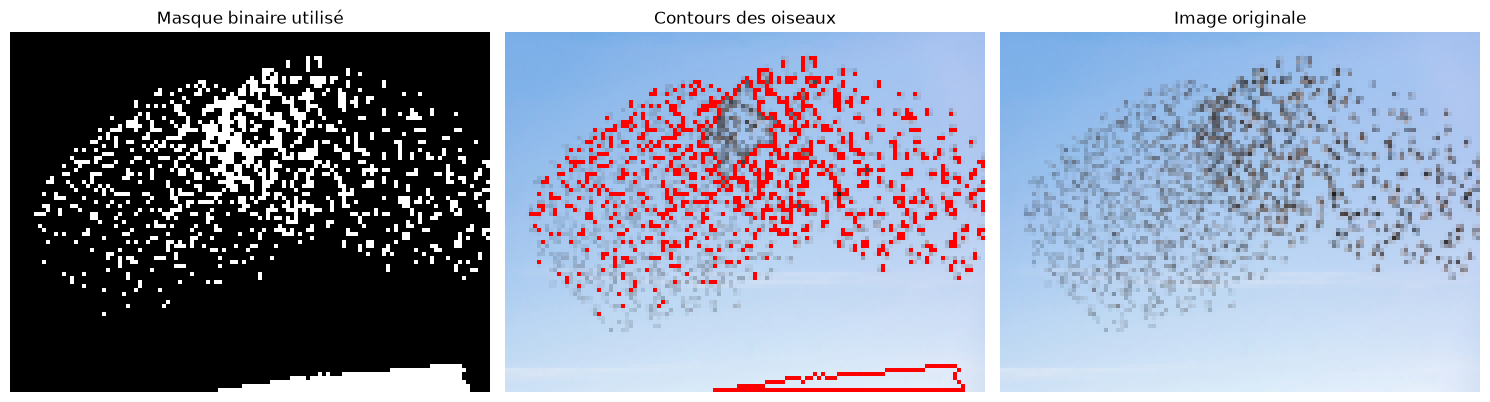

In [11]:
# Utiliser le masque des oiseaux (exemple : masque LAB)
mask = mask_birds_lab

# Trouver les contours
contours, _ = cv.findContours(mask, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)

# Dessiner les contours sur une copie de l'image
img_contours = img_small.copy()
cv.drawContours(img_contours, contours, -1, (255, 0, 0), 1)

# Afficher les résultats
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(mask, cmap='gray')
ax[0].set_title("Masque binaire utilisé")
ax[0].axis('off')

ax[1].imshow(img_contours)
ax[1].set_title("Contours des oiseaux")
ax[1].axis('off')

ax[2].imshow(img_small)
ax[2].set_title("Image originale")
ax[2].axis('off')

plt.tight_layout()
plt.show()

In [12]:
# Calculer l'aire et le périmètre de chaque contour
areas = [cv.contourArea(cnt) for cnt in contours]
perimeters = [cv.arcLength(cnt, True) for cnt in contours]

# Afficher les statistiques
print(f"Nombre d'oiseaux détectés : {len(contours)}")
print(f"Aire moyenne : {np.mean(areas):.2f} pixels")
print(f"Périmètre moyen : {np.mean(perimeters):.2f} pixels")

# Afficher les aires et périmètres de chaque contour
for i, (area, perimeter) in enumerate(zip(areas, perimeters)):
    print(f"Oiseau {i+1} : Aire = {area:.2f}, Périmètre = {perimeter:.2f}")

Nombre d'oiseaux détectés : 263
Aire moyenne : 2.43 pixels
Périmètre moyen : 5.58 pixels
Oiseau 1 : Aire = 205.00, Périmètre = 134.63
Oiseau 2 : Aire = 0.00, Périmètre = 0.00
Oiseau 3 : Aire = 0.00, Périmètre = 0.00
Oiseau 4 : Aire = 0.00, Périmètre = 2.83
Oiseau 5 : Aire = 0.00, Périmètre = 0.00
Oiseau 6 : Aire = 0.00, Périmètre = 0.00
Oiseau 7 : Aire = 0.00, Périmètre = 0.00
Oiseau 8 : Aire = 0.00, Périmètre = 0.00
Oiseau 9 : Aire = 0.00, Périmètre = 2.00
Oiseau 10 : Aire = 0.00, Périmètre = 0.00
Oiseau 11 : Aire = 0.00, Périmètre = 0.00
Oiseau 12 : Aire = 0.00, Périmètre = 4.83
Oiseau 13 : Aire = 0.00, Périmètre = 0.00
Oiseau 14 : Aire = 0.00, Périmètre = 2.00
Oiseau 15 : Aire = 0.00, Périmètre = 2.00
Oiseau 16 : Aire = 0.00, Périmètre = 0.00
Oiseau 17 : Aire = 0.00, Périmètre = 2.00
Oiseau 18 : Aire = 0.00, Périmètre = 0.00
Oiseau 19 : Aire = 0.00, Périmètre = 0.00
Oiseau 20 : Aire = 0.00, Périmètre = 2.00
Oiseau 21 : Aire = 0.00, Périmètre = 0.00
Oiseau 22 : Aire = 0.00, Périmètre

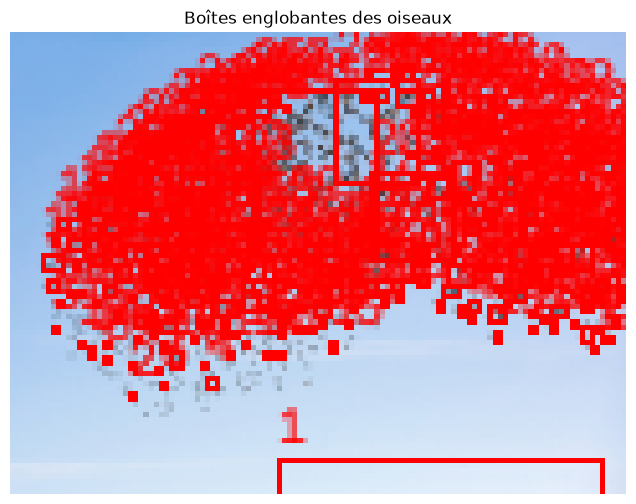

In [13]:
# Dessiner les boîtes englobantes
img_boxes = img_small.copy()
for i, cnt in enumerate(contours):
    x, y, w, h = cv.boundingRect(cnt)
    cv.rectangle(img_boxes, (x, y), (x + w, y + h), (255, 0, 0), 1)
    cv.putText(img_boxes, str(i + 1), (x, max(0, y - 3)), cv.FONT_HERSHEY_SIMPLEX, 0.35, (255, 0, 0), 1, cv.LINE_AA)

plt.figure(figsize=(10, 6))
plt.imshow(img_boxes)
plt.title("Boîtes englobantes des oiseaux")
plt.axis('off')
plt.show()

## 10. Morphologie mathématique (Bonus)

### Théorie
La **morphologie mathématique** permet de modifier la forme des objets dans une image binaire. Les opérations principales sont :
- **Érosion** : Réduit les objets (utile pour séparer des objets collés).
- **Dilatation** : Agrandit les objets (utile pour combler des trous).
- **Ouverture** : Érosion suivie de dilatation (lisse les contours).
- **Fermeture** : Dilatation suivie d'érosion (comble les petits trous).

**À faire** : appliquez une érosion suivie d'une dilatation sur le masque des oiseaux, puis recomptez les contours obtenus.

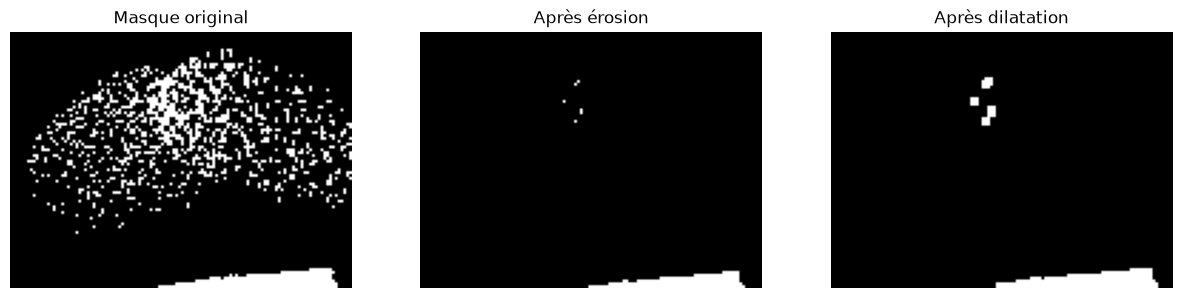

Nombre d'oiseaux après morphologie : 4


In [14]:
# Appliquer une érosion suivie d'une dilatation pour séparer les oiseaux collés
kernel = np.ones((3, 3), np.uint8)

# Érosion
mask_eroded = cv.erode(mask_birds_lab, kernel, iterations=1)

# Dilatation
mask_dilated = cv.dilate(mask_eroded, kernel, iterations=1)

# Afficher les résultats
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(mask_birds_lab, cmap='gray')
plt.title("Masque original")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(mask_eroded, cmap='gray')
plt.title("Après érosion")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(mask_dilated, cmap='gray')
plt.title("Après dilatation")
plt.axis('off')
plt.show()

# Trouver les contours après morphologie
contours_morph, _ = cv.findContours(mask_dilated, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)
print(f"Nombre d'oiseaux après morphologie : {len(contours_morph)}")

## Conclusion et prochaines étapes

### Résumé
Dans ce notebook, vous avez appris à :
- Charger et afficher des images avec OpenCV.
- Convertir entre différents espaces de couleur (BGR, RGB, LAB, HLS, Grayscale).
- Appliquer des transformations géométriques (redimensionnement, rotation, symétrie).
- Segmenter des images avec des seuillages (manuel, Otsu, adaptatif).
- Utiliser des masques pour isoler des objets (oiseaux vs ciel).
- Extraire et analyser des contours pour compter les oiseaux.
- Appliquer des opérations de morphologie mathématique.



### Ressources utiles
- [Documentation OpenCV](https://docs.opencv.org/4.x/)
---